# Análisis del Sistema Eléctrico Nacional (REE) 2019-2025

## 1. Análisis del problema

### 1.1. Identificación del sector y del problema planteado por el cliente
* **Sector:** Sector energético y eléctrico nacional.
* **Problema planteado:** En plena transición energética, la Cúpula Directiva necesita ir más allá de los informes descriptivos básicos. Requiere cruzar variables operativas complejas para evaluar si la inversión masiva en energías renovables está siendo eficiente, comprender cómo se comporta la red en momentos de máxima tensión y determinar si las anomalías o errores de calidad en los datos responden a patrones ocultos que afecten a la toma de decisiones estratégicas de infraestructura.

### 1.2. Información necesaria para la toma de decisiones
* Producción mensual de cada tecnología no renovable en los meses de menor generación solar, para saber cuáles actúan como respaldo.
* Comparativa real entre la potencia instalada (MW) y la energía producida (MWh) por la eólica y la solar.
* Saldo de los intercambios de electricidad con Francia, Portugal, Marruecos y Andorra en los meses de mayor demanda.
* Relación entre la producción mensual de viento y sol y la electricidad exportada a los países vecinos.
* Distribución de los registros marcados con incidencias de calidad (`revisar_valor_negativo`) por serie, fecha y territorio, para descartar sesgos en los análisis.

### 1.3. Preguntas de negocio formuladas
1. **El plan B cuando falla el sol:** En los meses en que la producción solar es más baja, ¿qué tecnologías no renovables suben para cubrir el hueco, y ha cambiado ese plan B entre 2019 y 2025?

2. **Rendimiento de las renovables:** Si comparamos la potencia instalada (MW) con la energía que realmente producen (MWh), ¿está siendo eficiente el crecimiento de parques solares y eólicos?

3. **Las fronteras en los meses críticos:** En el 10 % de los meses con mayor demanda del periodo, ¿necesitamos comprar electricidad a los países vecinos, y a cuál de ellos?

4. **A dónde va lo que sobra:** Los meses de mayor producción de viento y sol, ¿exportamos más electricidad? ¿Hay una correlación medible entre ambas cosas?

5. **Patrones en las anomalías:** Los registros marcados como `revisar_valor_negativo`, ¿son fallos aleatorios o se concentran en ciertas fechas, series o territorios?

### 1.4. Priorización de las preguntas
* **Prioridad Alta:** Preguntas 1 y 2 (Evaluación directa del mix energético y eficiencia).
* **Prioridad Media:** Preguntas 3 y 4 (Seguridad de red y flujos internacionales).
* **Prioridad Técnica:** Pregunta 5 (Calidad de datos).



## 2. Adquisición de los datos

### 2.1. Identificar su fuente

Para iniciar el proceso de análisis, es fundamental documentar y conocer el origen oficial de los datos que alimentarán nuestro pipeline de procesamiento.

* **Fuente:** Red Eléctrica de España (REE) / Operador del Sistema Eléctrico Nacional, a través de sus registros y plataformas públicas de monitorización del sistema eléctrico.

### 2.2. Identificar el formato en el que se encuentra

Conocer la estructuración de los ficheros de origen nos permite seleccionar el motor de lectura más adecuado para garantizar un rendimiento óptimo de procesamiento.

* **Formato:** Fichero estructurado en formato plano optimizado de alta eficiencia `.parquet`, el cual destaca por su compresión y velocidad en la lectura de grandes volúmenes de datos.

### 2.3. Cargar los datos utilizando las herramientas trabajadas en clase

Para realizar la ingesta de forma eficiente bajo un enfoque de Big Data, empleamos la librería `polars` de Python, la cual optimiza el uso de memoria y acelera la ejecución frente a métodos tradicionales.

In [1]:
%pip install polars pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import polars as pl

file_path = "../../ree_data/data/dataset_ree_limpio_transicion_energetica_2019_2025.parquet"

try:
    df = pl.read_parquet(file_path)
    print("Dataset cargado correctamente.")
except Exception as error:
    print(f"El dataset no se ha podido cargar: {error}")

Dataset cargado correctamente.


### 2.4. Comprobar que la carga se ha realizado correctamente

Una vez ejecutada la ingesta, realizamos un conjunto de validaciones técnicas indispensables para verificar la integridad de los datos. En este paso comprobaremos las dimensiones totales del dataset, visualizaremos una muestra representativa de las filas, validaremos el esquema de tipos asignados a cada columna y revisaremos el conteo de valores nulos.

In [3]:
print(f"Dimensiones del dataset cargado (Filas, Columnas): {df.shape}")

print("\n--- Muestra inicial de registros ---")
display(df.head(5))

print("\n--- Esquema del Dataset ---")
print(df.schema)

print("\n--- Conteo de Valores Nulos ---")
print(df.null_count())

Dimensiones del dataset cargado (Filas, Columnas): (171419, 20)

--- Muestra inicial de registros ---


datetime,date,year,month,time_granularity,geography_type,geography_name,border,system,category,endpoint,indicator_id,indicator_type,indicator_name,technology_id,technology_name,value,value_unit,percentage,quality_flag
"datetime[ns, Europe/Madrid]",str,i16,i8,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,str
2019-01-01 00:00:00 CET,"""2019-01-01""",2019,1,"""day""","""ccaa""","""Andalucía""","""No aplica""","""CCAA""","""balance""","""balance_electrico""","""10330""","""Hidráulica""","""Hidráulica""","""10330""","""Hidráulica""",25288.605,"""MWh""",0.029517,"""ok"""
2019-01-01 00:00:00 CET,"""2019-01-01""",2019,1,"""day""","""ccaa""","""Andalucía""","""No aplica""","""CCAA""","""balance""","""balance_electrico""","""10331""","""Carbón""","""Carbón""","""10331""","""Carbón""",808964.433,"""MWh""",0.410306,"""ok"""
2019-01-01 00:00:00 CET,"""2019-01-01""",2019,1,"""day""","""ccaa""","""Andalucía""","""No aplica""","""CCAA""","""balance""","""balance_electrico""","""10333""","""Eólica""","""Eólica""","""10333""","""Eólica""",547209.843,"""MWh""",0.638703,"""ok"""
2019-01-01 00:00:00 CET,"""2019-01-01""",2019,1,"""day""","""ccaa""","""Andalucía""","""No aplica""","""CCAA""","""balance""","""balance_electrico""","""10334""","""Otras renovables""","""Otras renovables""","""10334""","""Otras renovables""",109551.171,"""MWh""",0.127868,"""ok"""
2019-01-01 00:00:00 CET,"""2019-01-01""",2019,1,"""day""","""ccaa""","""Andalucía""","""No aplica""","""CCAA""","""balance""","""balance_electrico""","""10335""","""Cogeneración""","""Cogeneración""","""10335""","""Cogeneración""",474456.626,"""MWh""",0.240644,"""ok"""



--- Esquema del Dataset ---
Schema({'datetime': Datetime(time_unit='ns', time_zone='Europe/Madrid'), 'date': String, 'year': Int16, 'month': Int8, 'time_granularity': String, 'geography_type': String, 'geography_name': String, 'border': String, 'system': String, 'category': String, 'endpoint': String, 'indicator_id': String, 'indicator_type': String, 'indicator_name': String, 'technology_id': String, 'technology_name': String, 'value': Float64, 'value_unit': String, 'percentage': Float64, 'quality_flag': String})

--- Conteo de Valores Nulos ---
shape: (1, 20)
┌──────────┬──────┬──────┬───────┬───┬───────┬────────────┬────────────┬──────────────┐
│ datetime ┆ date ┆ year ┆ month ┆ … ┆ value ┆ value_unit ┆ percentage ┆ quality_flag │
│ ---      ┆ ---  ┆ ---  ┆ ---   ┆   ┆ ---   ┆ ---        ┆ ---        ┆ ---          │
│ u32      ┆ u32  ┆ u32  ┆ u32   ┆   ┆ u32   ┆ u32        ┆ u32        ┆ u32          │
╞══════════╪══════╪══════╪═══════╪═══╪═══════╪════════════╪════════════╪════════

## 3. Exploración de los datos

### 3.1. Mostrar una muestra de los datos

Para familiarizarnos visualmente con la estructura y el contenido que alberga el conjunto de datos, extraemos una muestra representativa con los primeros registros almacenados.

In [4]:
display(df.head(5))

datetime,date,year,month,time_granularity,geography_type,geography_name,border,system,category,endpoint,indicator_id,indicator_type,indicator_name,technology_id,technology_name,value,value_unit,percentage,quality_flag
"datetime[ns, Europe/Madrid]",str,i16,i8,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,str
2019-01-01 00:00:00 CET,"""2019-01-01""",2019,1,"""day""","""ccaa""","""Andalucía""","""No aplica""","""CCAA""","""balance""","""balance_electrico""","""10330""","""Hidráulica""","""Hidráulica""","""10330""","""Hidráulica""",25288.605,"""MWh""",0.029517,"""ok"""
2019-01-01 00:00:00 CET,"""2019-01-01""",2019,1,"""day""","""ccaa""","""Andalucía""","""No aplica""","""CCAA""","""balance""","""balance_electrico""","""10331""","""Carbón""","""Carbón""","""10331""","""Carbón""",808964.433,"""MWh""",0.410306,"""ok"""
2019-01-01 00:00:00 CET,"""2019-01-01""",2019,1,"""day""","""ccaa""","""Andalucía""","""No aplica""","""CCAA""","""balance""","""balance_electrico""","""10333""","""Eólica""","""Eólica""","""10333""","""Eólica""",547209.843,"""MWh""",0.638703,"""ok"""
2019-01-01 00:00:00 CET,"""2019-01-01""",2019,1,"""day""","""ccaa""","""Andalucía""","""No aplica""","""CCAA""","""balance""","""balance_electrico""","""10334""","""Otras renovables""","""Otras renovables""","""10334""","""Otras renovables""",109551.171,"""MWh""",0.127868,"""ok"""
2019-01-01 00:00:00 CET,"""2019-01-01""",2019,1,"""day""","""ccaa""","""Andalucía""","""No aplica""","""CCAA""","""balance""","""balance_electrico""","""10335""","""Cogeneración""","""Cogeneración""","""10335""","""Cogeneración""",474456.626,"""MWh""",0.240644,"""ok"""


### 3.2. Identificar las variables disponibles

Listamos el conjunto completo de columnas que componen el dataset para comprender el alcance de las métricas energéticas y temporales facilitadas por REE.

In [5]:
print("Variables disponibles en el dataset:")

for inicio in range(0, len(df.columns), 5):
    grupo = df.columns[inicio:inicio + 5]
    print(", ".join(grupo))

Variables disponibles en el dataset:
datetime, date, year, month, time_granularity
geography_type, geography_name, border, system, category
endpoint, indicator_id, indicator_type, indicator_name, technology_id
technology_name, value, value_unit, percentage, quality_flag


### 3.3. Identificar el tipo de cada variable

Consultamos el esquema técnico del dataset para verificar el tipo de dato asignado a cada columna (cadenas de texto, valores numéricos decimales o enteros, marcas temporales, etc.).

In [6]:
print("Esquema de tipos de datos:")

columnas = list(df.schema.items())

for inicio in range(0, len(columnas), 5):
    grupo = columnas[inicio:inicio + 5]
    print(", ".join(f"{nombre}: {tipo}" for nombre, tipo in grupo))

Esquema de tipos de datos:
datetime: Datetime(time_unit='ns', time_zone='Europe/Madrid'), date: String, year: Int16, month: Int8, time_granularity: String
geography_type: String, geography_name: String, border: String, system: String, category: String
endpoint: String, indicator_id: String, indicator_type: String, indicator_name: String, technology_id: String
technology_name: String, value: Float64, value_unit: String, percentage: Float64, quality_flag: String


### 3.4. Determinar el número de registros y columnas

Calculamos las dimensiones exactas de la matriz de datos para cuantificar el volumen global de información disponible para el análisis.

In [7]:
num_filas, num_columnas = df.shape
print(f"Número total de registros (filas): {num_filas}")
print(f"Número total de variables (columnas): {num_columnas}")

Número total de registros (filas): 171419
Número total de variables (columnas): 20


### 3.5. Analizar variables numéricas y categóricas

Clasificamos y separamos automáticamente las columnas del dataset según su naturaleza (variables cuantitativas numéricas, variables cualitativas categóricas o de texto y variables temporales) para planificar correctamente los futuros cruces y agregaciones.

In [8]:
numeric_cols = [col for col, dtype in df.schema.items() if dtype in [pl.Int64, pl.Int32, pl.Int16, pl.Int8, pl.Float64, pl.Float32]]
categorical_cols = [col for col, dtype in df.schema.items() if dtype in [pl.Utf8, pl.String]]

print(f"Total de variables numéricas ({len(numeric_cols)}):")
for inicio in range(0, len(numeric_cols), 5):
    print(", ".join(numeric_cols[inicio:inicio + 5]))

print(f"\nTotal de variables categóricas / texto ({len(categorical_cols)}):")
for inicio in range(0, len(categorical_cols), 5):
    print(", ".join(categorical_cols[inicio:inicio + 5]))

temporal_cols = [col for col, dtype in df.schema.items() if col not in numeric_cols and col not in categorical_cols]

print(f"\nTotal de variables temporales ({len(temporal_cols)}):")
print(", ".join(temporal_cols))

Total de variables numéricas (4):
year, month, value, percentage

Total de variables categóricas / texto (15):
date, time_granularity, geography_type, geography_name, border
system, category, endpoint, indicator_id, indicator_type
indicator_name, technology_id, technology_name, value_unit, quality_flag

Total de variables temporales (1):
datetime


### 3.6. Obtener estadísticas descriptivas

Generamos un resumen estadístico global para examinar las tendencias centrales, valores mínimos, máximos y la dispersión de las métricas numéricas del sistema eléctrico.

In [9]:
display(df.describe())

statistic,datetime,date,year,month,time_granularity,geography_type,geography_name,border,system,category,endpoint,indicator_id,indicator_type,indicator_name,technology_id,technology_name,value,value_unit,percentage,quality_flag
str,str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,str
"""count""","""171419""","""171419""",171419.0,171419.0,"""171419""","""171419""","""171419""","""171419""","""171419""","""171419""","""171419""","""171419""","""171419""","""171419""","""171419""","""171419""",171419.0,"""171419""",171419.0,"""171419"""
"""null_count""","""0""","""0""",0.0,0.0,"""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""",0.0,"""0""",0.0,"""0"""
"""mean""","""2022-07-03 01:29:52.681091+02:…",null,2022.024694,6.512563,null,null,null,null,null,null,null,null,null,null,null,null,101014.808561,null,0.520441,null
"""std""",null,null,2.002746,3.455006,null,null,null,null,null,null,null,null,null,null,null,null,373666.725624,null,0.426529,null
"""min""","""2019-01-01 00:00:00+01:00""","""2019-01-01""",2019.0,1.0,"""day""","""ccaa""","""Andalucía""","""Andorra""","""CCAA""","""balance""","""balance_electrico""","""1""","""Carbón""","""Carbón""","""1""","""Carbón""",-3.1061e6,"""MW""",0.0,"""ok"""
"""25%""","""2020-10-01 00:00:00+02:00""",null,2020.0,4.0,null,null,null,null,null,null,null,null,null,null,null,null,0.261,null,0.058678,null
"""50%""","""2022-07-04 00:00:00+02:00""",null,2022.0,7.0,null,null,null,null,null,null,null,null,null,null,null,null,577.3,null,0.471618,null
"""75%""","""2024-04-01 00:00:00+02:00""",null,2024.0,10.0,null,null,null,null,null,null,null,null,null,null,null,null,21235.522,null,1.0,null
"""max""","""2025-12-31 00:00:00+01:00""","""2025-12-31""",2025.0,12.0,"""month""","""system""","""Sistema eléctrico""","""Portugal""","""Sistema eléctrico""","""intercambios""","""potencia_instalada""","""Portugal""","""saldo""","""saldo""","""Portugal""","""saldo""",4.4464e6,"""MWh""",1.0,"""revisar_valor_negativo"""


## 4. Integración de los datos

### 4.1. Identificar qué datasets pueden relacionarse entre sí

En el análisis de los sistemas eléctricos de Red Eléctrica de España (REE), la información suele dividirse en múltiples dimensiones operativas (generación por tecnologías, demanda e intercambios internacionales). Identificamos qué subconjuntos o fuentes de datos del ecosistema REE pueden cruzarse para obtener una visión global y unificada del sistema energético.

In [10]:
endpoints_a_integrar = ["estructura_generacion", "demanda_evolucion", "intercambios_francia_fisicos"]

print("Bloques de datos que se van a relacionar:")
display(
    df.filter(pl.col("endpoint").is_in(endpoints_a_integrar))
    .group_by(["endpoint", "time_granularity", "value_unit"])
    .agg(pl.len().alias("n_filas"))
    .sort("endpoint")
)

Bloques de datos que se van a relacionar:


endpoint,time_granularity,value_unit,n_filas
str,str,str,u32
"""demanda_evolucion""","""month""","""MWh""",1596
"""estructura_generacion""","""month""","""MWh""",12721
"""intercambios_francia_fisicos""","""day""","""MWh""",7671


### 4.2. Identificar los campos que permiten establecer las relaciones

Para poder realizar uniones (*joins*) o agregaciones consistentes entre las diferentes métricas del sistema, es necesario localizar los atributos comunes que actúan como nexo relacional (claves temporales y territoriales).

In [11]:
claves_relacion = ["year", "month"]
print(f"Campos clave seleccionados para las operaciones relacionales: {claves_relacion}")

Campos clave seleccionados para las operaciones relacionales: ['year', 'month']


### 4.3. Realizar las operaciones JOIN necesarias

Utilizamos las capacidades de cruce y agregación relacional optimizadas de `polars` para unificar las distintas dimensiones operativas y métricas del sistema eléctrico bajo un mismo esquema estructurado.

In [12]:
# Generación mensual de toda España (sin la fila de total, para no contarla dos veces)
generacion_mensual = (
    df.filter(
        (pl.col("endpoint") == "estructura_generacion")
        & (pl.col("technology_name") != "Generación total")
    )
    .group_by(claves_relacion)
    .agg(pl.col("value").sum().alias("generacion_mwh"))
)

# Demanda mensual de toda España
demanda_mensual = (
    df.filter(pl.col("endpoint") == "demanda_evolucion")
    .group_by(claves_relacion)
    .agg(pl.col("value").sum().alias("demanda_mwh"))
)

# Saldo mensual de intercambios con los cuatro países (datos diarios pasados a meses)
intercambios_mensual = (
    df.filter(
        pl.col("endpoint").str.contains("fisicos")
        & (pl.col("technology_name") == "saldo")
    )
    .group_by(claves_relacion)
    .agg(pl.col("value").sum().alias("saldo_intercambios_mwh"))
)

try:
    df_integrado = (
        generacion_mensual
        .join(demanda_mensual, on=claves_relacion, how="inner")
        .join(intercambios_mensual, on=claves_relacion, how="inner")
        .sort(claves_relacion)
    )
except Exception as error:
    print(f"La operación no se ha realizado: {error}")
else:
    print("La operación se ha realizado correctamente.")

La operación se ha realizado correctamente.


### 4.4. Construir un dataset integrado

Generamos oficialmente el dataset consolidado resultante de las operaciones anteriores, el cual servirá como base única y centralizada para la fase de análisis avanzado y visualización.

In [13]:
print(f"Dimensiones del dataset integrado resultante: {df_integrado.shape}")
display(df_integrado.head(5))

Dimensiones del dataset integrado resultante: (84, 5)


year,month,generacion_mwh,demanda_mwh,saldo_intercambios_mwh
i16,i8,f64,f64,f64
2019,1,2.3829e7,2.3742e7,246353.446
2019,2,1.9920e7,2.0574e7,1.0118e6
2019,3,2.0215e7,2.1183e7,1.3922e6
2019,4,1.9070e7,1.9990e7,1.0911e6
2019,5,1.9648e7,2.0397e7,747800.537


### 4.5. Comprobación de que la integración se ha realizado correctamente

Realizamos una auditoría técnica sobre el dataset integrado para verificar que no se han introducido duplicidades anómalas, que el volumen de filas es coherente y que la presencia de valores nulos está controlada.

In [14]:
print(f"Número total de registros integrados: {df_integrado.height} (se esperan 84: 12 meses x 7 años)")
print(f"Meses repetidos: {df_integrado.height - df_integrado.select(claves_relacion).unique().height}")
print("\n--- Verificación de nulos en el dataset integrado ---")
print(df_integrado.null_count())

Número total de registros integrados: 84 (se esperan 84: 12 meses x 7 años)
Meses repetidos: 0

--- Verificación de nulos en el dataset integrado ---
shape: (1, 5)
┌──────┬───────┬────────────────┬─────────────┬────────────────────────┐
│ year ┆ month ┆ generacion_mwh ┆ demanda_mwh ┆ saldo_intercambios_mwh │
│ ---  ┆ ---   ┆ ---            ┆ ---         ┆ ---                    │
│ u32  ┆ u32   ┆ u32            ┆ u32         ┆ u32                    │
╞══════╪═══════╪════════════════╪═════════════╪════════════════════════╡
│ 0    ┆ 0     ┆ 0              ┆ 0           ┆ 0                      │
└──────┴───────┴────────────────┴─────────────┴────────────────────────┘


### 4.6. Explicar qué información nueva permite obtener el dataset integrado

En el dataset original, la generación, la demanda y los intercambios internacionales están en filas y endpoints distintos, y además con diferente granularidad temporal. El dataset integrado aporta:

* **Una visión conjunta por mes:** cada fila reúne cuánta electricidad se generó, cuánta se consumió y cuál fue el saldo de intercambios con los países vecinos, algo que no se puede ver directamente en los datos originales.
* **Una granularidad común:** los intercambios, que son diarios, se han pasado a meses para poder compararlos con la generación y la demanda, que son mensuales.
* **Una base para el análisis:** el mismo método de unión por año y mes es el que se aplica en la Fase 5 para cruzar potencia con energía, demanda con intercambios y producción renovable con exportación.

## 5. Análisis y visualización

### 5.1. Responder a las preguntas de negocio planteadas inicialmente

En esta sección abordamos y damos respuesta estructurada a las 5 hipótesis y preguntas de negocio planteadas en la Fase 1, cruzando las métricas operativas del sistema eléctrico.

**Nota sobre la granularidad temporal:** durante la exploración se ha comprobado que los datos de generación, demanda y potencia instalada de las comunidades autónomas son mensuales. En el caso del endpoint `balance_electrico`, las filas de las comunidades están etiquetadas como `day` pero solo contienen 84 fechas distintas, es decir, una por mes. Los únicos datos realmente diarios son los intercambios internacionales y los de Ceuta y Melilla. Por este motivo todas las preguntas se responden a nivel mensual.

In [15]:
display(
    df.filter(pl.col("endpoint") == "balance_electrico")
    .group_by("geography_type")
    .agg(pl.col("date").n_unique().alias("fechas_distintas"))
)

geography_type,fechas_distintas
str,u32
"""melilla""",2557
"""ceuta""",2557
"""ccaa""",84


### 5.1.1. **El plan B cuando falla el sol:**
En los meses en que la producción solar es más baja, ¿qué tecnologías no renovables suben para cubrir el hueco, y ha cambiado ese plan B entre 2019 y 2025?

**Objetivo analítico:** Identificar los meses del año con menor producción solar y comparar, en 2019 y en 2025, cuánto produce cada tecnología no renovable en esos meses frente al resto del año.

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Generación mensual de toda España por tecnología
gen = (
    df.filter(pl.col("endpoint") == "estructura_generacion")
    .group_by(["year", "month", "technology_name"])
    .agg(pl.col("value").sum().alias("energia_mwh"))
)

# 2. Producción solar acumulada por mes del año, de menor a mayor
solar_por_mes = (
    gen.filter(pl.col("technology_name").str.contains("Solar"))
    .group_by("month")
    .agg(pl.col("energia_mwh").sum().alias("solar_total_mwh"))
    .sort("solar_total_mwh")
)

print("--- Producción solar por mes del año (de menor a mayor) ---")
display(solar_por_mes)



--- Producción solar por mes del año (de menor a mayor) ---


month,solar_total_mwh
i8,f64
1,9.5576e6
12,9.8014e6
11,1.1506e7
2,1.2662e7
3,1.5172e7
…,…
9,2.1279e7
5,2.4848e7
6,2.5547e7


In [17]:
meses_poco_sol = [11, 12, 1, 2]

no_renovables = ["Carbón", "Ciclo combinado", "Cogeneración", "Motores diésel",
                 "Nuclear", "Residuos no renovables", "Turbina de gas", "Turbina de vapor"]

gen_no_renovable = (
    gen.filter(pl.col("technology_name").is_in(no_renovables))
    .with_columns(
        pl.when(pl.col("month").is_in(meses_poco_sol))
        .then(pl.lit("Meses de poco sol"))
        .otherwise(pl.lit("Resto del año"))
        .alias("periodo")
    )
)

p1_resultado = (
    gen_no_renovable
    .group_by(["year", "technology_name", "periodo"])
    .agg((pl.col("energia_mwh").mean() / 1000).alias("media_gwh"))
    .sort(["year", "technology_name", "periodo"])
)
pl.Config.set_tbl_rows(40)
display(p1_resultado.filter(pl.col("year").is_in([2019, 2025])))

year,technology_name,periodo,media_gwh
i16,str,str,f64
2019,"""Carbón""","""Meses de poco sol""",1723.099494
2019,"""Carbón""","""Resto del año""",722.279928
2019,"""Ciclo combinado""","""Meses de poco sol""",3084.843886
2019,"""Ciclo combinado""","""Resto del año""",4511.283839
2019,"""Cogeneración""","""Meses de poco sol""",2322.77802
2019,"""Cogeneración""","""Resto del año""",2318.075282
2019,"""Motores diésel""","""Meses de poco sol""",239.754059
2019,"""Motores diésel""","""Resto del año""",260.375142
2019,"""Nuclear""","""Meses de poco sol""",4396.397748


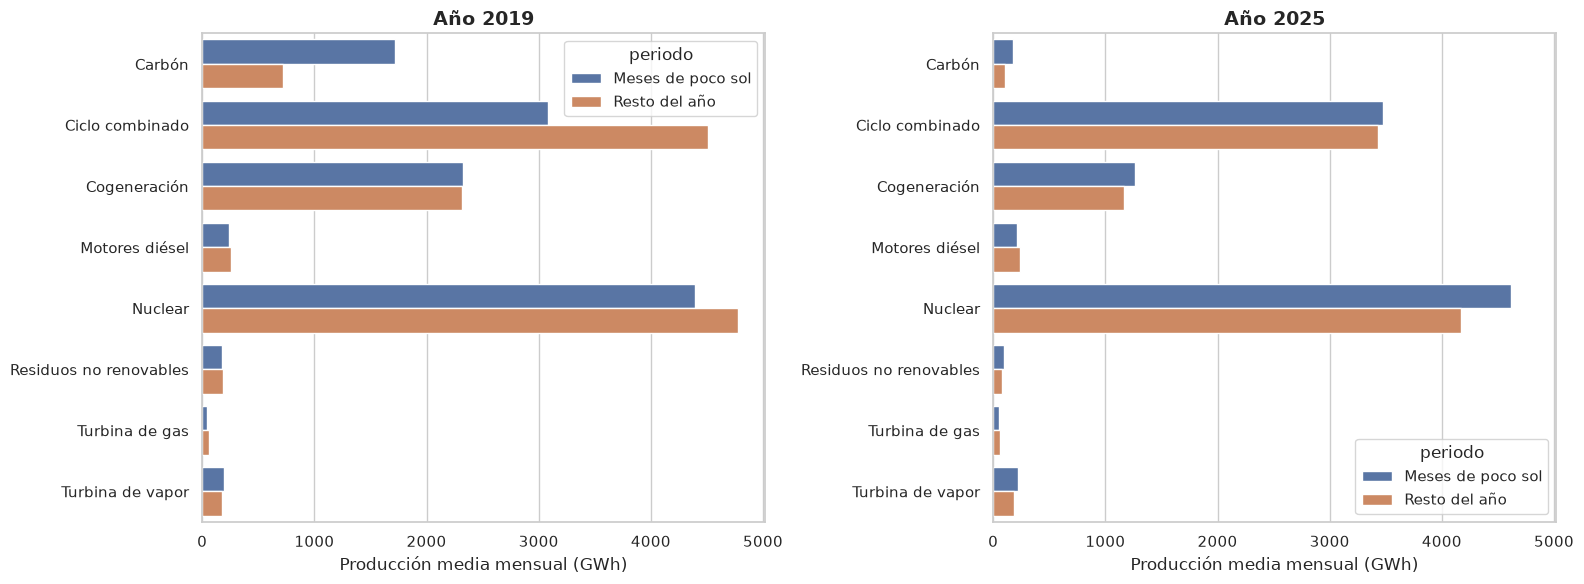

In [18]:
df_2019 = p1_resultado.filter(pl.col("year") == 2019).to_pandas()
df_2025 = p1_resultado.filter(pl.col("year") == 2025).to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

sns.barplot(data=df_2019, x="media_gwh", y="technology_name", hue="periodo", ax=axes[0])
axes[0].set_title("Año 2019", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Producción media mensual (GWh)", fontsize=12)
axes[0].set_ylabel("")

sns.barplot(data=df_2025, x="media_gwh", y="technology_name", hue="periodo", ax=axes[1])
axes[1].set_title("Año 2025", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Producción media mensual (GWh)", fontsize=12)
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Respuesta a la pregunta:**

Los cuatro meses con menor producción solar son noviembre, diciembre, enero y febrero. Comparando la producción de las tecnologías no renovables en esos meses frente al resto del año, se observa que el "plan B" ha cambiado claramente entre 2019 y 2025:

* **En 2019 el respaldo era el carbón.** Producía de media 1.723 GWh al mes en los meses de poco sol, frente a 722 GWh el resto del año, es decir, más del doble.
* **En 2025 el carbón prácticamente ha desaparecido.** Su producción es residual en ambos periodos (173 GWh al mes en los meses de poco sol y 103 GWh el resto del año), por lo que ya no actúa como respaldo.
* **La nuclear es ahora la que más aumenta.** En 2025 produce 4.617 GWh al mes en los meses de poco sol frente a 4.173 GWh el resto del año, mientras que en 2019 ocurría lo contrario (4.396 GWh frente a 4.780 GWh).
* **El ciclo combinado ha cambiado de papel.** En 2019 producía bastante menos en los meses de poco sol (3.085 GWh frente a 4.511 GWh). En 2025 produce prácticamente lo mismo en ambos periodos (3.474 GWh frente a 3.431 GWh).

**Conclusión:** el sistema ha dejado de apoyarse en el carbón para cubrir los meses de menor producción solar. En 2025 ninguna tecnología no renovable hace un refuerzo tan marcado como el que hacía el carbón en 2019.

### 5.1.2. **Rendimiento de las renovables:**
Si comparamos la potencia instalada (MW) con la energía que realmente producen (MWh), ¿está siendo eficiente el crecimiento de parques solares y eólicos?

**Objetivo analítico:** Cruzar la potencia instalada con la energía generada por la eólica, la solar fotovoltaica y la solar térmica, y calcular su factor de capacidad anual para comprobar si cada MW instalado rinde lo mismo a medida que crece la potencia.

In [19]:
potencia = (
    df.filter(pl.col("endpoint") == "potencia_instalada")
    .group_by(["year", "month", "technology_name"])
    .agg(pl.col("value").sum().alias("potencia_mw"))
    .sort(["year", "month", "technology_name"])
)

print(df.filter(pl.col("endpoint") == "potencia_instalada")["value_unit"].unique().to_list())
print(potencia["technology_name"].unique().sort().to_list())
display(potencia.head(15))

['MW']
['Carbón', 'Ciclo combinado', 'Cogeneración', 'Eólica', 'Fuel + Gas', 'Hidroeólica', 'Hidráulica', 'Motores diésel', 'Nuclear', 'Otras renovables', 'Potencia instalada total', 'Residuos no renovables', 'Residuos renovables', 'Solar fotovoltaica', 'Solar térmica', 'Turbina de gas', 'Turbina de vapor']


year,month,technology_name,potencia_mw
i16,i8,str,f64
2019,1,"""Carbón""",10030.285
2019,1,"""Ciclo combinado""",22986.435
2019,1,"""Cogeneración""",5494.788
2019,1,"""Eólica""",23212.203
2019,1,"""Fuel + Gas""",7.95
2019,1,"""Hidroeólica""",11.32
2019,1,"""Hidráulica""",17029.212
2019,1,"""Motores diésel""",747.16
2019,1,"""Nuclear""",7117.29


In [20]:
renovables = ["Eólica", "Solar fotovoltaica", "Solar térmica"]

potencia_anual = (
    potencia.filter(pl.col("technology_name").is_in(renovables))
    .group_by(["year", "technology_name"])
    .agg(pl.col("potencia_mw").mean().alias("potencia_media_mw"))
)

energia_anual = (
    gen.filter(pl.col("technology_name").is_in(renovables))
    .group_by(["year", "technology_name"])
    .agg(pl.col("energia_mwh").sum().alias("energia_mwh"))
)

p2_resultado = (
    potencia_anual
    .join(energia_anual, on=["year", "technology_name"], how="inner")
    .with_columns(
        (pl.col("energia_mwh") / pl.col("potencia_media_mw")).alias("horas_equivalentes")
    )
    .with_columns(
        (pl.col("horas_equivalentes") / 8760 * 100).alias("factor_capacidad_pct")
    )
    .sort(["technology_name", "year"])
)

display(p2_resultado)

year,technology_name,potencia_media_mw,energia_mwh,horas_equivalentes,factor_capacidad_pct
i16,str,f64,f64,f64,f64
2019,"""Eólica""",23870.55,5.3720e7,2250.491758,25.690545
2020,"""Eólica""",26326.9325,5.4474e7,2069.147589,23.620406
2021,"""Eólica""",27843.353417,6.0087e7,2158.024424,24.634982
2022,"""Eólica""",29238.499667,6.0784e7,2078.905627,23.731799
2023,"""Eólica""",30225.80375,6.2274e7,2060.281214,23.519192
2024,"""Eólica""",31146.124417,6.0556e7,1944.261921,22.194771
2025,"""Eólica""",32531.51975,5.8397e7,1795.085631,20.491845
2019,"""Solar fotovoltaica""",5414.372917,8.0672e6,1489.95938,17.008669
2020,"""Solar fotovoltaica""",9321.293833,1.3450e7,1442.977054,16.472341


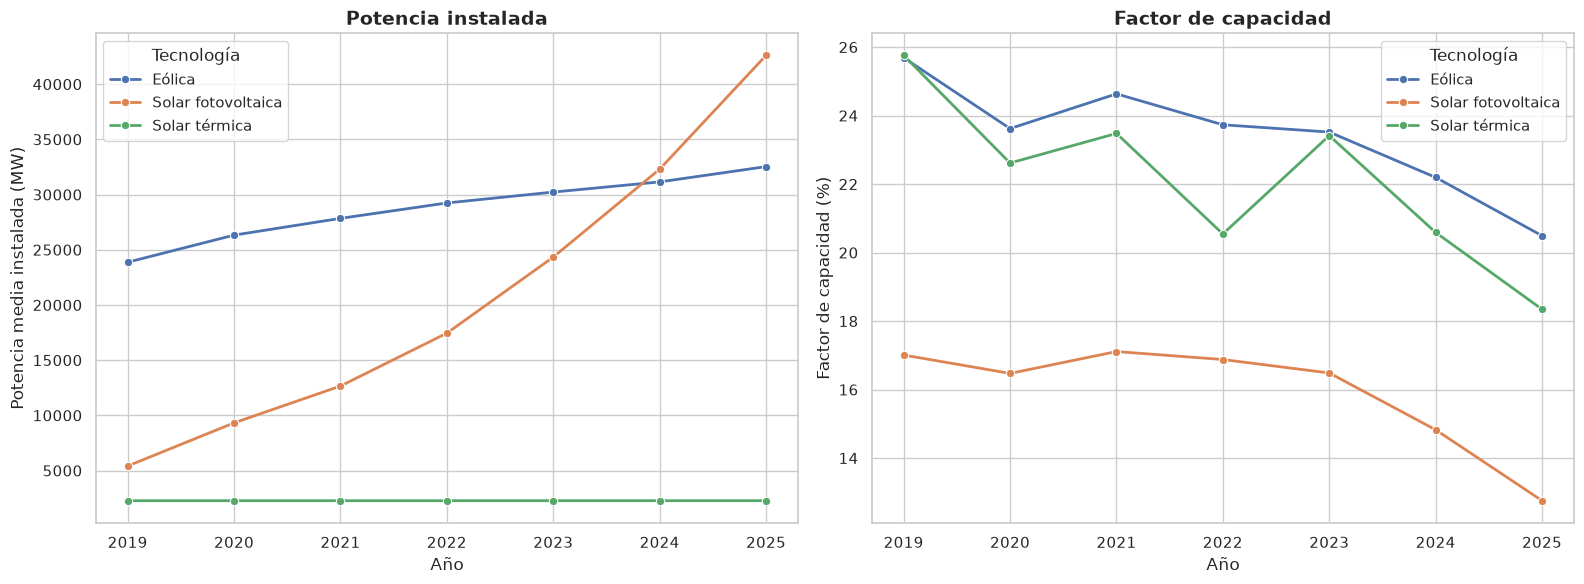

In [21]:
df_p2 = p2_resultado.to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.lineplot(data=df_p2, x="year", y="potencia_media_mw", hue="technology_name", marker="o", linewidth=2, ax=axes[0])
axes[0].set_title("Potencia instalada", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Año", fontsize=12)
axes[0].set_ylabel("Potencia media instalada (MW)", fontsize=12)
axes[0].legend(title="Tecnología")

sns.lineplot(data=df_p2, x="year", y="factor_capacidad_pct", hue="technology_name", marker="o", linewidth=2, ax=axes[1])
axes[1].set_title("Factor de capacidad", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Año", fontsize=12)
axes[1].set_ylabel("Factor de capacidad (%)", fontsize=12)
axes[1].legend(title="Tecnología")

plt.tight_layout()
plt.show()

**Respuesta a la pregunta:**

Para medir la eficiencia se ha calculado el factor de capacidad: el porcentaje de la energía máxima posible que cada tecnología produce realmente con su potencia instalada.

* **La potencia instalada ha crecido mucho, sobre todo la fotovoltaica.** Pasa de 5.414 MW en 2019 a 42.607 MW en 2025, casi ocho veces más, y desde 2024 supera a la eólica (32.300 MW frente a 31.146 MW). La eólica crece de 23.871 MW a 32.532 MW. La solar térmica no ha crecido (2.271 MW todo el periodo).
* **El rendimiento por MW instalado ha bajado.** El factor de capacidad de la fotovoltaica se mantiene entre el 16,5 % y el 17,1 % hasta 2023, pero cae al 14,8 % en 2024 y al 12,8 % en 2025. El de la eólica baja del 25,7 % al 20,5 %.
* **La solar térmica también baja sin haber instalado nada nuevo** (del 25,8 % al 18,3 %), con altibajos entre años.

**Conclusión:** el crecimiento ha sido muy grande en capacidad, pero no igual de eficiente en producción. En los dos últimos años cada MW instalado genera menos energía que al principio del periodo, por lo que la energía producida crece más despacio que la potencia.

### 5.1.3. **Las fronteras en los meses críticos:**
En el 10 % de los meses con mayor demanda del periodo, ¿necesitamos comprar electricidad a los países vecinos, y a cuál de ellos?

**Objetivo analítico:** Identificar el 10 % de los meses con mayor demanda eléctrica y comparar el saldo de intercambios físicos con Francia, Portugal, Marruecos y Andorra en esos meses frente al resto.

In [22]:
# Demanda mensual de toda España
demanda = (
    df.filter(pl.col("endpoint") == "demanda_evolucion")
    .group_by(["year", "month"])
    .agg(pl.col("value").sum().alias("demanda_mwh"))
    .sort(["year", "month"])
)

# Intercambios físicos con los cuatro países vecinos
fisicos = df.filter(pl.col("endpoint").str.contains("fisicos"))

print(f"Meses con datos de demanda: {demanda.height}")

# Comprobación del signo de cada serie
display(
    fisicos.group_by(["border", "technology_name"])
    .agg([
        pl.col("value").min().alias("minimo"),
        pl.col("value").max().alias("maximo"),
    ])
    .sort(["border", "technology_name"])
)

Meses con datos de demanda: 84


border,technology_name,minimo,maximo
str,str,f64,f64
"""Andorra""","""Exportación""",-1651.65,0.0
"""Andorra""","""Importación""",0.0,6.25
"""Andorra""","""saldo""",-1651.65,0.49
"""Francia""","""Exportación""",-79306.37,0.0
"""Francia""","""Importación""",0.0,81103.224
"""Francia""","""saldo""",-74543.187,80534.206
"""Marruecos""","""Exportación""",-21423.096,0.0
"""Marruecos""","""Importación""",0.0,12358.7
"""Marruecos""","""saldo""",-21423.096,12358.7


In [23]:
# Saldo mensual con cada país (los datos originales son diarios)
saldo_mensual = (
    fisicos.filter(pl.col("technology_name") == "saldo")
    .group_by(["year", "month", "border"])
    .agg(pl.col("value").sum().alias("saldo_mwh"))
)

# Marcamos el 10 % de meses con mayor demanda
umbral = demanda["demanda_mwh"].quantile(0.90)

demanda_marcada = demanda.with_columns(
    pl.when(pl.col("demanda_mwh") >= umbral)
    .then(pl.lit("Meses de máxima demanda"))
    .otherwise(pl.lit("Resto de meses"))
    .alias("tipo_mes")
)

print(f"Umbral del 10 % de meses con más demanda: {umbral:,.0f} MWh")
display(demanda_marcada.filter(pl.col("tipo_mes") == "Meses de máxima demanda"))

# Saldo medio mensual con cada país según el tipo de mes
p3_resultado = (
    saldo_mensual
    .join(demanda_marcada, on=["year", "month"], how="inner")
    .group_by(["tipo_mes", "border"])
    .agg((pl.col("saldo_mwh").mean() / 1000).alias("saldo_medio_gwh"))
    .sort(["border", "tipo_mes"])
)

display(p3_resultado)

# Saldo total sumando los cuatro países
p3_total = (
    p3_resultado
    .group_by("tipo_mes")
    .agg(pl.col("saldo_medio_gwh").sum().alias("saldo_total_gwh"))
    .sort("tipo_mes")
)

display(p3_total)

Umbral del 10 % de meses con más demanda: 22,034,208 MWh


year,month,demanda_mwh,tipo_mes
i16,i8,f64,str
2019,1,2.3742e7,"""Meses de máxima demanda"""
2019,7,2.3307e7,"""Meses de máxima demanda"""
2020,1,2.3017e7,"""Meses de máxima demanda"""
2020,7,2.2303e7,"""Meses de máxima demanda"""
2021,1,2.3094e7,"""Meses de máxima demanda"""
2021,7,2.2034e7,"""Meses de máxima demanda"""
2022,7,2.2767e7,"""Meses de máxima demanda"""
2025,1,2.2122e7,"""Meses de máxima demanda"""
2025,7,2.2579e7,"""Meses de máxima demanda"""


tipo_mes,border,saldo_medio_gwh
str,str,f64
"""Meses de máxima demanda""","""Andorra""",-19.4257
"""Resto de meses""","""Andorra""",-19.084913
"""Meses de máxima demanda""","""Francia""",345.755126
"""Resto de meses""","""Francia""",139.749713
"""Meses de máxima demanda""","""Marruecos""",-54.623316
"""Resto de meses""","""Marruecos""",-112.390774
"""Meses de máxima demanda""","""Portugal""",-507.706135
"""Resto de meses""","""Portugal""",-590.429318


tipo_mes,saldo_total_gwh
str,f64
"""Meses de máxima demanda""",-236.000025
"""Resto de meses""",-582.155293


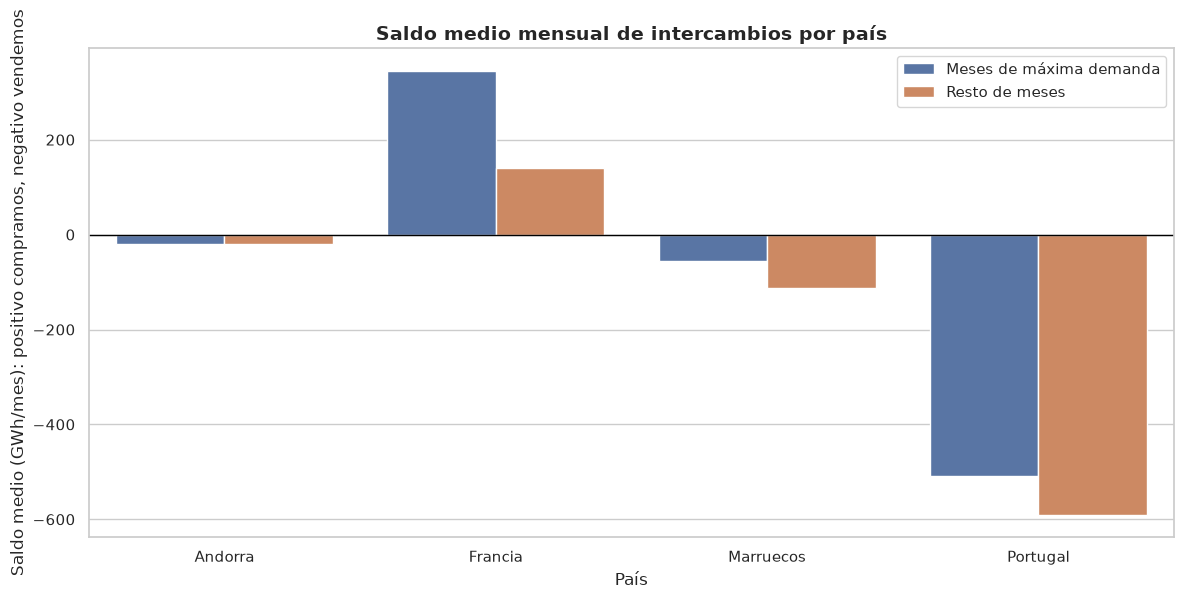

In [24]:
df_p3 = p3_resultado.to_pandas()

plt.figure(figsize=(12, 6))
sns.barplot(data=df_p3, x="border", y="saldo_medio_gwh", hue="tipo_mes")
plt.axhline(0, color="black", linewidth=1)
plt.title("Saldo medio mensual de intercambios por país", fontsize=14, fontweight='bold')
plt.xlabel("País", fontsize=12)
plt.ylabel("Saldo medio (GWh/mes): positivo compramos, negativo vendemos", fontsize=12)
plt.legend(title="")
plt.tight_layout()
plt.show()

**Respuesta a la pregunta:**

El 10 % de los meses con mayor demanda son 9 meses, todos ellos enero o julio. Es decir, los picos de consumo en España se producen en pleno invierno y en pleno verano.

En el saldo de intercambios, un valor positivo significa que compramos más electricidad de la que vendemos a ese país, y un valor negativo que vendemos más de la que compramos:

* **Francia es el único país al que compramos.** En los meses de máxima demanda el saldo medio es de +346 GWh al mes, frente a +140 GWh en el resto de meses: unas 2,5 veces más.
* **A Portugal le vendemos siempre**, aunque algo menos en los meses críticos (−508 GWh frente a −590 GWh).
* **A Marruecos también le vendemos**, y en los meses críticos la mitad que en el resto (−55 GWh frente a −112 GWh).
* **Con Andorra el saldo no cambia** (−19 GWh en ambos casos).

**Conclusión:** España no está obligada a comprar electricidad para cubrir sus meses de mayor demanda, porque sumando las cuatro fronteras sigue vendiendo más de lo que compra (−236 GWh al mes). Sin embargo, ese saldo vendedor se reduce a menos de la mitad respecto al resto de meses (−582 GWh): en los momentos críticos se compra mucho más a Francia y se vende menos a Portugal y Marruecos. Francia es, por tanto, el apoyo exterior del sistema cuando la demanda aprieta.

### 5.1.4. **A dónde va lo que sobra:**
Los meses de mayor producción de viento y sol, ¿exportamos más electricidad? ¿Hay una correlación medible entre ambas cosas?

**Objetivo analítico:** Calcular para cada mes la producción eólica y solar y la electricidad exportada a los países vecinos, y medir la correlación entre ambas series.

In [25]:
# Producción mensual de eólica + solar
viento_sol = (
    gen.filter(pl.col("technology_name").is_in(["Eólica", "Solar fotovoltaica", "Solar térmica"]))
    .group_by(["year", "month"])
    .agg(pl.col("energia_mwh").sum().alias("viento_sol_mwh"))
)

# Exportación mensual a los cuatro países (viene en negativo, la pasamos a positivo)
exportacion = (
    fisicos.filter(pl.col("technology_name") == "Exportación")
    .group_by(["year", "month"])
    .agg((pl.col("value").sum() * -1).alias("exportacion_mwh"))
)

# Unimos las dos por año y mes
p4_datos = (
    viento_sol
    .join(exportacion, on=["year", "month"], how="inner")
    .sort(["year", "month"])
)

print(f"Meses: {p4_datos.height}")
display(p4_datos.head(12))

Meses: 84


year,month,viento_sol_mwh,exportacion_mwh
i16,i8,f64,f64
2019,1,6.5795e6,1.3341e6
2019,2,4.4985e6,1.0465e6
2019,3,6.1013e6,1.0370e6
2019,4,5.6243e6,731500.828
2019,5,6.2406e6,825508.186
2019,6,4.8766e6,581410.392
2019,7,4.9815e6,588923.28
2019,8,4.4625e6,929433.737
2019,9,5.0474e6,1.1438e6


In [26]:
p4_resultado = p4_datos.select(
    pl.corr("viento_sol_mwh", "exportacion_mwh").alias("correlacion")
)

display(p4_resultado)

correlacion
f64
0.741853


In [27]:
p4_por_anio = (
    p4_datos
    .group_by("year")
    .agg(pl.corr("viento_sol_mwh", "exportacion_mwh").alias("correlacion"))
    .sort("year")
)

display(p4_por_anio)

year,correlacion
i16,f64
2019,0.6027
2020,0.775482
2021,0.650212
2022,0.05858
2023,0.563567
2024,0.653422
2025,0.440936


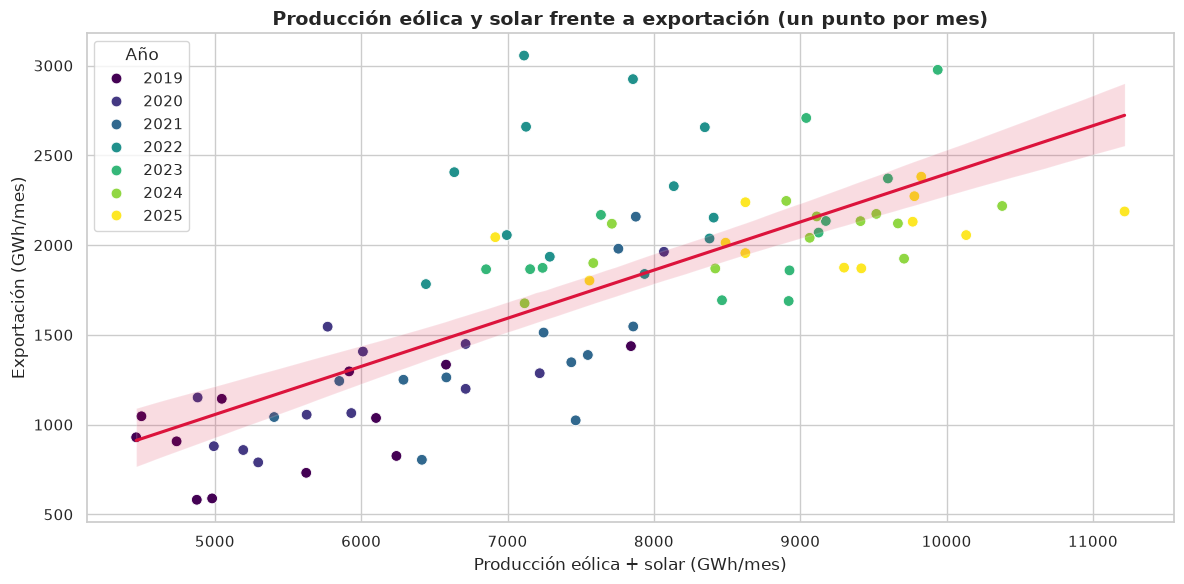

In [28]:
df_p4 = p4_datos.with_columns([
    (pl.col("viento_sol_mwh") / 1000).alias("viento_sol_gwh"),
    (pl.col("exportacion_mwh") / 1000).alias("exportacion_gwh"),
]).to_pandas()

plt.figure(figsize=(12, 6))
sns.scatterplot(data=df_p4, x="viento_sol_gwh", y="exportacion_gwh", hue="year", palette="viridis", s=60)
sns.regplot(data=df_p4, x="viento_sol_gwh", y="exportacion_gwh", scatter=False, color="crimson")
plt.title("Producción eólica y solar frente a exportación (un punto por mes)", fontsize=14, fontweight='bold')
plt.xlabel("Producción eólica + solar (GWh/mes)", fontsize=12)
plt.ylabel("Exportación (GWh/mes)", fontsize=12)
plt.legend(title="Año")
plt.tight_layout()
plt.show()

**Respuesta a la pregunta:**

Sí, existe una correlación positiva y medible. Considerando los 84 meses del periodo, el coeficiente de correlación de Pearson entre la producción eólica y solar y la electricidad exportada es de **0,74**, lo que indica una relación fuerte: los meses con más viento y sol tienden a ser los meses en que más se exporta.

Como las dos magnitudes han crecido entre 2019 y 2025, se ha comprobado si la relación se mantiene dentro de cada año, para descartar que se deba solo a esa tendencia común:

* **En seis de los siete años la correlación es positiva y de moderada a fuerte**, entre 0,44 (2025) y 0,78 (2020).
* **La excepción es 2022, con una correlación de 0,06**, prácticamente nula. Ese año se registraron las exportaciones más altas del periodo (hasta unos 3.000 GWh en un mes) también en meses de producción renovable normal.

**Conclusión:** cuando hay más producción de viento y sol, España exporta más electricidad, y esta relación se repite año tras año. No es una relación perfecta: la producción renovable explica una parte de las exportaciones, pero hay otros factores que también influyen, como demuestra 2022.

### 5.1.5. **Patrones en las anomalías:**
Los registros marcados como `revisar_valor_negativo`, ¿son fallos aleatorios o se concentran en ciertas fechas, series o territorios?

**Objetivo analítico:** Cuantificar los registros marcados con la incidencia de calidad y analizar cómo se reparten por serie, por año y por territorio, para determinar si siguen un patrón.

In [29]:
anomalias = df.filter(pl.col("quality_flag") == "revisar_valor_negativo")

porcentaje = anomalias.height / df.height * 100
print(f"Registros marcados: {anomalias.height} de {df.height} ({porcentaje:.2f} %)")

display(
    anomalias.group_by(["endpoint", "technology_name"])
    .agg([
        pl.len().alias("n_anomalias"),
        pl.col("value").min().alias("valor_minimo"),
        pl.col("value").max().alias("valor_maximo"),
    ])
    .sort("n_anomalias", descending=True)
)

Registros marcados: 198 de 171419 (0.12 %)


endpoint,technology_name,n_anomalias,valor_minimo,valor_maximo
str,str,u32,f64,f64
"""estructura_generacion""","""Carbón""",83,-9303.234,-228.811
"""estructura_generacion_emisione…","""Carbón""",83,-9303.234,-228.811
"""estructura_generacion""","""Ciclo combinado""",11,-1358.179,-865.078
"""estructura_generacion_emisione…","""Ciclo combinado""",11,-1358.179,-865.078
"""estructura_generacion""","""Fuel + Gas""",5,-0.001,-0.001
"""estructura_generacion_emisione…","""Fuel + Gas""",5,-0.001,-0.001


In [30]:
# Nos quedamos con un solo endpoint para no contar cada anomalía dos veces
anomalias_unicas = anomalias.filter(pl.col("endpoint") == "estructura_generacion")

p5_por_anio = (
    anomalias_unicas
    .group_by(["year", "technology_name"])
    .agg(pl.len().alias("n_anomalias"))
    .sort(["year", "technology_name"])
)

p5_por_territorio = (
    anomalias_unicas
    .group_by(["geography_name", "technology_name"])
    .agg(pl.len().alias("n_anomalias"))
    .sort("n_anomalias", descending=True)
)

print(f"Anomalías distintas: {anomalias_unicas.height}")
display(p5_por_anio)
display(p5_por_territorio)

Anomalías distintas: 99


year,technology_name,n_anomalias
i16,str,u32
2019,"""Carbón""",14
2019,"""Ciclo combinado""",2
2019,"""Fuel + Gas""",3
2020,"""Carbón""",29
2020,"""Ciclo combinado""",6
2020,"""Fuel + Gas""",1
2021,"""Carbón""",26
2021,"""Ciclo combinado""",3
2021,"""Fuel + Gas""",1


geography_name,technology_name,n_anomalias
str,str,u32
"""Islas Baleares""","""Carbón""",27
"""Castilla y León""","""Carbón""",18
"""Andalucía""","""Carbón""",17
"""Galicia""","""Carbón""",12
"""Aragón""","""Carbón""",9
"""Comunidad Valenciana""","""Fuel + Gas""",5
"""Aragón""","""Ciclo combinado""",5
"""La Rioja""","""Ciclo combinado""",5
"""Galicia""","""Ciclo combinado""",1


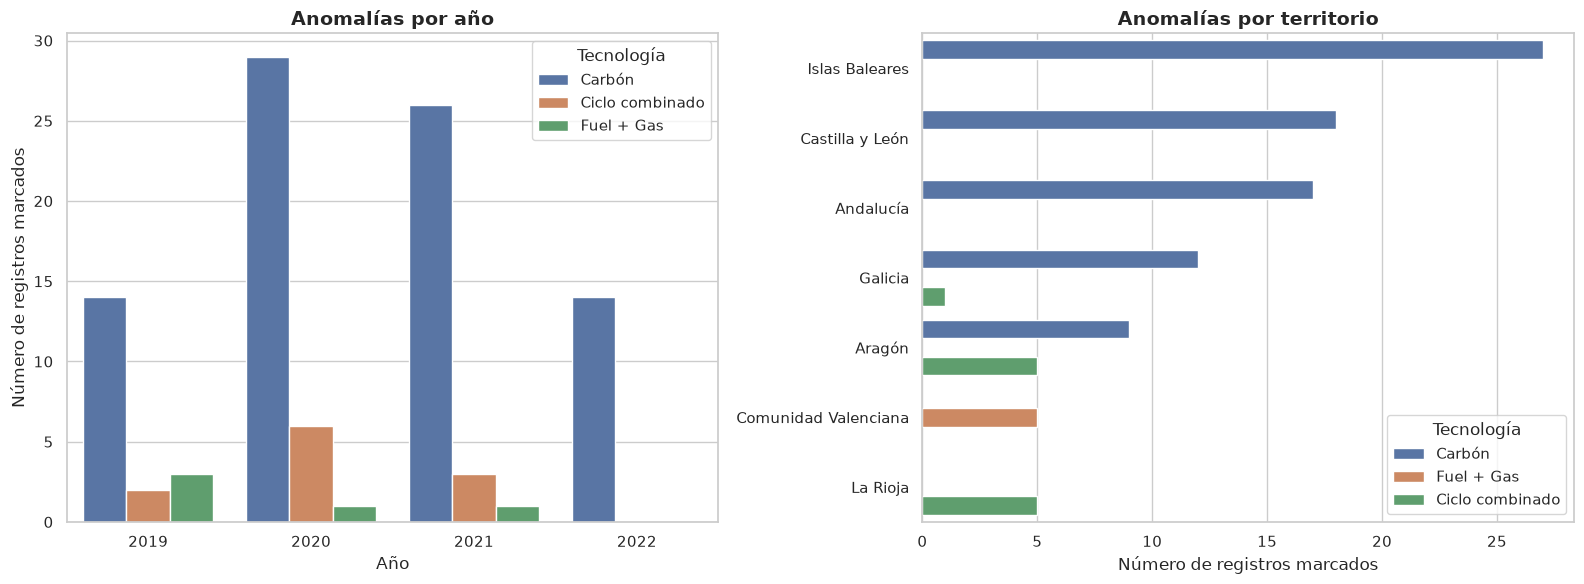

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=p5_por_anio.to_pandas(), x="year", y="n_anomalias", hue="technology_name", ax=axes[0])
axes[0].set_title("Anomalías por año", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Año", fontsize=12)
axes[0].set_ylabel("Número de registros marcados", fontsize=12)
axes[0].legend(title="Tecnología")

sns.barplot(data=p5_por_territorio.to_pandas(), x="n_anomalias", y="geography_name", hue="technology_name", ax=axes[1])
axes[1].set_title("Anomalías por territorio", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Número de registros marcados", fontsize=12)
axes[1].set_ylabel("")
axes[1].legend(title="Tecnología")

plt.tight_layout()
plt.show()

**Respuesta a la pregunta:**

No son fallos aleatorios: se concentran claramente en ciertas series, fechas y territorios.

* **Son muy pocos registros.** Hay 198 marcados de 171.419 (un 0,12 %). Además, cada uno aparece repetido en dos endpoints (`estructura_generacion` y `estructura_generacion_emisiones`), por lo que en realidad son 99 anomalías distintas.
* **Se concentran en tres tecnologías.** 83 de las 99 corresponden al carbón (un 84 %), 11 al ciclo combinado y 5 a fuel + gas. Ninguna otra serie del dataset tiene registros marcados.
* **Se concentran entre 2019 y 2022.** Hay 19 en 2019, 36 en 2020, 30 en 2021 y 14 en 2022. Entre 2023 y 2025 no hay ninguna.
* **Se concentran en 7 territorios.** Las de carbón están en Islas Baleares (27), Castilla y León (18), Andalucía (17), Galicia (12) y Aragón (9).

**Conclusión:** las anomalías siguen un patrón muy definido: son valores negativos de generación en tecnologías no renovables, sobre todo carbón, durante los primeros años del periodo y en comunidades concretas. Esto indica que no se trata de errores al azar, sino de un comportamiento sistemático de esas series. Al ser tan pocos registros y de valor pequeño (el mayor es de −9.303 MWh frente a generaciones mensuales de millones de MWh), no afectan a las conclusiones de las preguntas anteriores.